In [48]:
import numpy as np 
import pandas as pd


# Simple Linear Regression Project: Predicting Sales from Advertising

**Goal:** a company spends money on advertising on **TV**, **radio** and in **newspapers**. We want to **predict how many products it will sell** for a given advertising budget.

**Type of problem:** supervised learning → **regression** (sales is a number).

**Dataset:** `Advertising.csv` (200 rows), stored in this folder. Source: *An Introduction to Statistical Learning* (statlearning.com).

| Column | Meaning |
|---|---|
| TV | Money spent on TV ads (in thousands of dollars) |
| radio | Money spent on radio ads (in thousands of dollars) |
| newspaper | Money spent on newspaper ads (in thousands of dollars) |
| **sales** | **Target:** products sold (in thousands of units) |

### Steps
1. Import libraries
2. Load and check the data
3. Quick look at the data (one chart)
4. Split into inputs (X) and output (y)
5. Train/test split
6. Build (train) the model
7. Understand the model (equation)
8. Make predictions
9. Evaluate the model
10. Predict for a new advertising budget
11. Conclusion

> **How to read the code:** lines starting with `#` are comments, notes for humans that Python ignores. Run the cells from top to bottom with **Shift + Enter**.


In [5]:
df = pd.read_csv("D:/AJAY_PYTHON/Python/ML/data/Advertising.csv")

In [6]:
df.head()

,Unnamed: 0,TV,radio,newspaper,sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


In [7]:
print("Shape", df.shape)

Shape (200, 5)


In [8]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Unnamed: 0    0
TV            0
radio         0
newspaper     0
sales         0
dtype: int64


In [9]:
print("Duplicate rows: ")
print(df.duplicated().sum())

Duplicate rows: 
0


In [10]:
# Basic statistics for each column .. avg, min, max, median
df.describe()

,Unnamed: 0,TV,radio,newspaper,sales
count,200.000000,200.000000,200.000000,200.000000,200.000000
mean,100.500000,147.042500,23.264000,30.554000,14.022500
std,57.879185,85.854236,14.846809,21.778621,5.217457
min,1.000000,0.700000,0.000000,0.300000,1.600000
25%,50.750000,74.375000,9.975000,12.750000,10.375000
50%,100.500000,149.750000,22.900000,25.750000,12.900000
75%,150.250000,218.825000,36.525000,45.100000,17.400000
max,200.000000,296.400000,49.600000,114.000000,27.000000


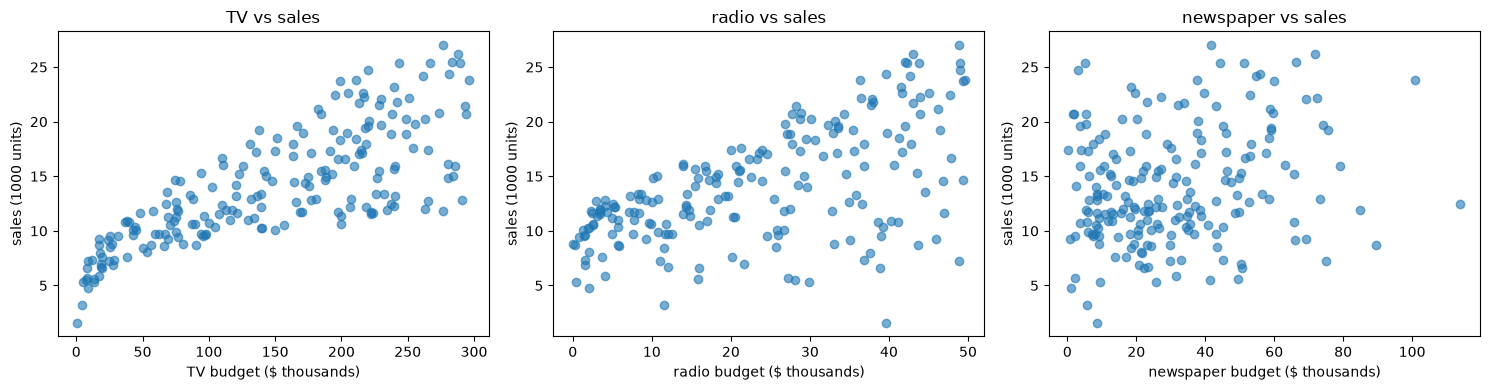

Correlation with sales:
Unnamed: 0   -0.05
TV            0.78
radio         0.58
newspaper     0.23
sales         1.00
Name: sales, dtype: float64


In [11]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1,3, figsize =(15,4))

for a, col in zip(ax, ["TV", "radio", "newspaper"]):
    a.scatter(df[col], df["sales"], alpha=0.60)
    a.set_xlabel(f"{col} budget ($ thousands)")
    a.set_ylabel("sales (1000 units)")
    a.set_title(f"{col} vs sales")
    
plt.tight_layout()
plt.show()

print("Correlation with sales:")
print(df.corr()["sales"].round(2))

In [12]:
df.head()

,Unnamed: 0,TV,radio,newspaper,sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


In [15]:
df.columns


Index(['Unnamed: 0', 'TV', 'radio', 'newspaper', 'sales'], dtype='str')

In [16]:
x = df[['TV', 'radio', 'newspaper']]
y =df[['sales']]

In [18]:
x.head()

,TV,radio,newspaper
0,230.1,37.8,69.2
1,44.5,39.3,45.1
2,17.2,45.9,69.3
3,151.5,41.3,58.5
4,180.8,10.8,58.4


In [22]:
y.head()

,sales
0,22.1
1,10.4
2,9.3
3,18.5
4,12.9


In [24]:
from sklearn.model_selection import train_test_split

In [25]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state =42)

In [26]:
x_train.shape

(160, 3)

In [27]:
x_test.shape

(40, 3)

In [28]:
y_train.shape

(160, 1)

In [35]:
y_test.shape

(40, 1)

In [29]:

from sklearn.linear_model import LinearRegression

In [30]:
# Initializing Linear Regression model which we imported from sklearn library

model = LinearRegression()

In [31]:
# training the model
model.fit(x_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 3)","[[0.04,0.19,0. ]]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['TV','radio','newspaper']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[2.98]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)


In [32]:
# y = slope, intercept

intercept = np.ravel(model.intercept_)[0]
print("Intercept:", round(float(intercept), 3))



Intercept: 2.979


In [39]:
for name, coef in zip(x.columns, np.ravel(model.coef_)):
    print(f"Coefficient for {name:9s}: {coef:.4f}")

Coefficient for TV       : 0.0447
Coefficient for radio    : 0.1892
Coefficient for newspaper: 0.0028


In [43]:
# y = mx + b
# y = b + b1x1 + b2b2 + b3x3

b0 = np.ravel(model.intercept_)[0]
b1, b2, b3 = np.ravel(model.coef_)
print(f"\nEquation: sales = {b0:.3f} + {b1:.4f}×TV + {b2:.4f}×radio + {b3:.4f}×newspaper")


Equation: sales = 2.979 + 0.0447×TV + 0.1892×radio + 0.0028×newspaper


In [44]:
y_pred = model.predict(x_test)

In [45]:
y_pred

array([[16.4080242 ],
       [20.88988209],
       [21.55384318],
       [10.60850256],
       [22.11237326],
       [13.10559172],
       [21.05719192],
       [ 7.46101034],
       [13.60634581],
       [15.15506967],
       [ 9.04831992],
       [ 6.65328312],
       [14.34554487],
       [ 8.90349333],
       [ 9.68959028],
       [12.16494386],
       [ 8.73628397],
       [16.26507258],
       [10.27759582],
       [18.83109103],
       [19.56036653],
       [13.25103464],
       [12.33620695],
       [21.30695132],
       [ 7.82740305],
       [ 5.80957448],
       [20.75753231],
       [11.98138077],
       [ 9.18349576],
       [ 8.5066991 ],
       [12.46646769],
       [10.00337695],
       [21.3876709 ],
       [12.24966368],
       [18.26661538],
       [20.13766267],
       [14.05514005],
       [20.85411186],
       [11.0174441 ],
       [ 4.56899622]])

In [46]:
y_test

,sales
95,16.9
15,22.4
30,21.4
158,7.3
128,24.7
115,12.6
69,22.3
170,8.4
174,11.5
45,14.9


In [ ]:
compare = pd.DataFrame({
    "Actual sales": np.ravel(y_test),
    "Predicted sales": np.round(np.ravel(y_pred), 2),
})
#  Error = actual value - predicted value
compare["Error"] = (compare["Actual sales"] - compare["Predicted sales"]).round(2)
compare.head(10)

,Actual sales,Predicted sales,Error
0,16.9,16.41,0.49
1,22.4,20.89,1.51
2,21.4,21.55,-0.15
3,7.3,10.61,-3.31
4,24.7,22.11,2.59
5,12.6,13.11,-0.51
6,22.3,21.06,1.24
7,8.4,7.46,0.94
8,11.5,13.61,-2.11
9,14.9,15.16,-0.26


: 